# Esfuerzo para pagar la hipoteca de una vivienda

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"  # carpeta en research/temas/
GRAFICA_ID = "esfuerzo-compra-hipoteca"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Esfuerzo para pagar la hipoteca de una vivienda"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "solo_espana"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de la renta disponible del hogar"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Qué parte de la renta disponible del hogar mediano se iría en las cuotas del primer año de un préstamo hipotecario estándar, por el 80 % del valor, para comprar una vivienda tipo de precio medio. Es el «esfuerzo teórico anual» del Banco de España, sin descontar deducciones fiscales.

**Cómo se lee.** Un valor de 35 significa que las cuotas se llevarían el 35 % de la renta del hogar. Recoge a la vez el precio de la vivienda, la renta de los hogares y el tipo de interés de las hipotecas.

**Limitaciones.**
- Es un cálculo teórico con un hogar, una vivienda y un préstamo tipo; no es lo que pagan los hogares que ya tienen hipoteca.
- Las hipótesis del préstamo (porcentaje financiado, plazo y tipo de interés) son las de la metodología del Banco de España.
- Solo España: no hay un indicador equivalente en las fuentes internacionales autorizadas.

## 2. Descarga

Serie `D_TKB57210_IPV` del Boletín Estadístico del Banco de España (esfuerzo teórico anual sin deducciones), trimestral; el fetcher calcula la media de cada año completo.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import bde


def descargar():
    """Devuelve (DataFrame `serie, periodo, valor`, lista de FuenteMeta)."""
    return bde.get({'D_TKB57210_IPV': "espana"}, agregacion='media', desde=DESDE)


df, fuentes = descargar()

## 3. Transformación

Los datos ya vienen en la unidad final: solo se pasan a años naturales en la descarga (ver notas).

In [ ]:
NOTAS = [
    'Banco de España, indicadores de accesibilidad a la vivienda: esfuerzo teórico anual sin deducciones fiscales, en porcentaje de la renta disponible del hogar.',
    'Supone el hogar mediano, que compra una vivienda tipo con un préstamo hipotecario estándar por el 80 % de su valor; las demás hipótesis del préstamo son las de la metodología del Banco de España.',
    'Serie trimestral: se usa la media de los cuatro trimestres de cada año; el año en curso, incompleto, no se incluye.',
    'Solo España: no hay un indicador equivalente en las fuentes internacionales autorizadas.',
]

## 4. Visualización

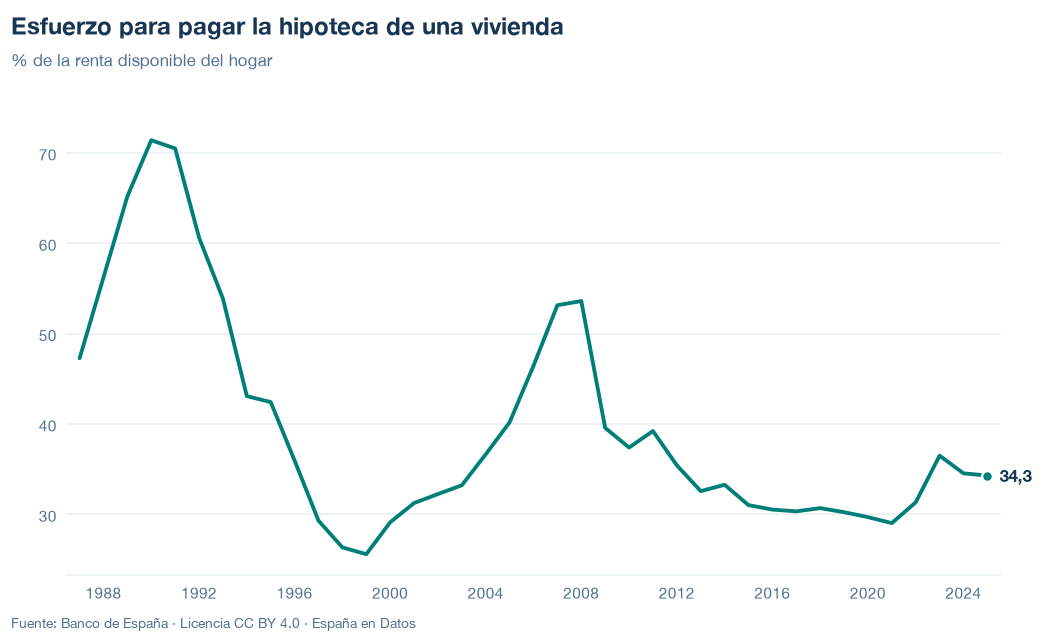

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/esfuerzo-compra-hipoteca.json y data/esfuerzo-compra-hipoteca.csv


## 6. Fuentes, notas y licencia

- Banco de España, Boletín Estadístico, serie `D_TKB57210_IPV` (indicadores de accesibilidad a la vivienda).

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.